Task 1

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='whitegrid')

date_columns = ['last_scraped', 'calendar_last_scraped', 'first_review', 'last_review']
listings = pd.read_csv('data/listings_clean.csv', parse_dates=date_columns)

fig, ax = plt.subplots()
ax.hist(listings['number_of_reviews'], bins=50)
plt.show()



In [ ]:
fig, ax = plt.subplots()

sns.histplot(data=listings, x='number_of_reviews', bins=50, ax=ax)

ax.set_title('Most listings have few reviews')
ax.set_xlabel('Number of reviews')
ax.set_ylabel('Number of listings')

plt.show()

#How is it different?
# Both charts show the exact same shape but the matplotlib chart has no title and no axis labels. 
# The seaborn chart looks cleaner and more informative

Task 2

In [ ]:
median = listings['number_of_reviews'].median()
mean = listings['number_of_reviews'].mean()

q1 = listings['number_of_reviews'].quantile(0.25)
q3 = listings['number_of_reviews'].quantile(0.75)
upper = q3 + 1.5 * (q3 - q1)

print('Median:', round(median, 1))
print('Mean:', round(mean, 1))
print('Upper fence:', round(upper, 1))

fig, ax = plt.subplots()
sns.histplot(data=listings, x='number_of_reviews', bins=50, ax=ax)

ax.axvline(median, color='black', linestyle='--', label=f'median {median:,.0f}')
ax.axvline(mean, color='red', linestyle='--', label=f'mean {mean:,.0f}')
ax.axvline(upper, color='gray', linestyle=':', label=f'upper fence {upper:,.0f}')

ax.set_title('The mean is higher than the median')
ax.set_xlabel('Number of reviews')
ax.set_ylabel('Number of listings')
ax.legend()

plt.show()

# The upper fence (70) is the furthest to the right of the three lines
# The mean (36) is further to the right than the median (9) because a few listings with very many reviews pull the average up

Task 3

In [ ]:
listings['reviews_outlier'] = listings['number_of_reviews'] > upper
n_outliers = listings['reviews_outlier'].sum()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.histplot(data=listings, x='number_of_reviews', bins=50, ax=axes[0])
sns.histplot(data=listings[~listings['reviews_outlier']], x='number_of_reviews', bins=50, ax=axes[1])

axes[0].set_title('All listings')
axes[1].set_title(f'Without the {n_outliers} outliers')

for ax in axes:
    ax.set_xlabel('Number of reviews')
    ax.set_ylabel('Number of listings')

plt.tight_layout()
plt.show()

# The left chart is stretched to 1293 reviews because of long tail 
# The right chart shows only values up to 69 reviews. It lets us see the real shape of most listings

Task 4

In [ ]:
two_types = listings[listings['room_type'].isin(['Entire home/apt', 'Private room'])]

fig, ax = plt.subplots(figsize=(8, 5))
sns.boxplot(data=two_types, x='room_type', y='number_of_reviews', ax=ax)
ax.set_ylim(0, 300)

above_300 = (two_types['number_of_reviews'] > 300).sum()
ax.set_title(f'{above_300} listings with more than 300 reviews are outside the picture')
ax.set_xlabel('Room type')
ax.set_ylabel('Number of reviews')

# Private rooms have the higher median (12 reviews vs 8 for Entire home/apt) 

Task 5

In [ ]:
order = listings['room_type'].value_counts().index

fig, ax = plt.subplots(figsize=(8, 5))

sns.countplot(data=listings, y='room_type', order=order, ax=ax)

ax.set_title('Entire homes/apts are the biggest')

plt.tight_layout()
plt.show()

In [ ]:
by_area = (
    listings.groupby('neighbourhood_cleansed')['number_of_reviews']
    .agg(['median', 'count'])
    .sort_values('median', ascending=False)
    .reset_index()
)

by_area['label'] = by_area['neighbourhood_cleansed'] + ' (' + by_area['count'].astype(str) + ')'

fig, ax = plt.subplots(figsize=(8, 5))

sns.barplot(data=by_area, x='median', y='label', ax=ax)

ax.set_title('Södermalms has the highest median')
ax.set_xlabel('Median number of reviews')
ax.set_ylabel('')

plt.tight_layout()
plt.show()
# Södermalms also has the most listings (1145)

Task 6

In [ ]:
above_300 = (listings['number_of_reviews'] > 300).sum()

fig, ax = plt.subplots(figsize=(8, 5))

sns.scatterplot(data=listings, x='availability_365', y='number_of_reviews', alpha=0.3, ax=ax)

ax.set_ylim(0, 300)
ax.set_title(f'Availability and number of reviews are weakly related\n({above_300} listings above 300 reviews are outside the picture)')
ax.set_xlabel('Availability (days per year)')
ax.set_ylabel('Number of reviews')

plt.show()

In [ ]:
two_types = listings[listings['room_type'].isin(['Entire home/apt', 'Private room'])]
above_300_two = (two_types['number_of_reviews'] > 300).sum()

fig, ax = plt.subplots(figsize=(8, 5))

sns.scatterplot(data=two_types, x='availability_365', y='number_of_reviews', alpha=0.3, hue='room_type', ax=ax)

ax.set_ylim(0, 300)
ax.set_title(f'Both room types show the same weak pattern\n({above_300_two} listings above 300 reviews are outside the picture)')
ax.set_xlabel('Availability (days per year)')
ax.set_ylabel('Number of reviews')

plt.show()

In [ ]:
# The dots form a wide cloud, mostly near the bottom (few reviews), spread from 0 to 365 days. 
# There is no clear line, so the pattern is weak. This matches the low correlation of 0.18. 
# In the second chart both room types overlap a lot (91 listings are above 300 reviews).

Task 7

In [ ]:
cols = [
    'number_of_reviews', 'price', 'accommodates', 'bedrooms',
    'availability_365', 'review_scores_rating', 'minimum_nights', 'days_since_review'
]

corr = listings[cols].corr()

fig, ax = plt.subplots(figsize=(8, 6))

sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, ax=ax)

ax.set_title('Number of reviews is only weakly correlated with other columns')

plt.tight_layout()
plt.show()

In [ ]:
by_year = listings['last_review'].dt.year.value_counts().sort_index()
print(by_year)

fig, ax = plt.subplots(figsize=(8, 5))

sns.lineplot(x=by_year.index, y=by_year.values, marker='o', ax=ax)

ax.set_title('Most reviewed listings got their last review in 2026')
ax.set_xlabel('Year of last review')
ax.set_ylabel('Number of listings')

plt.tight_layout()
plt.show()

# The line is almost flat from 2014 to 2022, then goes up and 2026 is much higher than all other years.
# It means these listings are still active and getting new reviews

Task 8

         room_type  median  count
0  Entire home/apt    4.92   3229
1     Private room    4.89    675


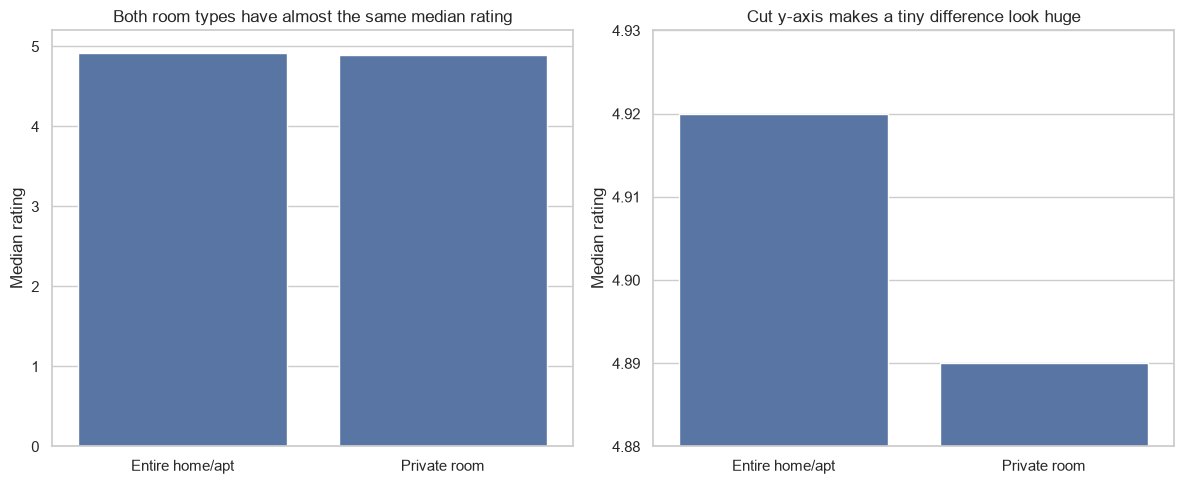

In [29]:
two_types = listings[listings['room_type'].isin(['Entire home/apt', 'Private room'])]

medians = (
    two_types.groupby('room_type')['review_scores_rating']
    .agg(['median', 'count'])
    .reset_index()
)
print(medians)

# 1. The same two bars twice
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.barplot(data=medians, x='room_type', y='median', ax=axes[0])
axes[0].set_ylim(0, 5.2)
axes[0].set_title('Both room types have almost the same median rating')
axes[0].set_xlabel('')
axes[0].set_ylabel('Median rating')

sns.barplot(data=medians, x='room_type', y='median', ax=axes[1])
axes[1].set_ylim(4.88, 4.93)
axes[1].set_title('Cut y-axis makes a tiny difference look huge')
axes[1].set_xlabel('')
axes[1].set_ylabel('Median rating')

plt.tight_layout()
plt.show()

# 2. Save the honest chart as rating_per_room_type.png
fig_honest, ax = plt.subplots(figsize=(8, 5))
sns.barplot(data=medians, x='room_type', y='median', ax=ax)
ax.set_ylim(0, 5.2)
ax.set_title('Both room types have almost the same median rating')
ax.set_xlabel('')
ax.set_ylabel('Median rating')

fig_honest.savefig('rating_per_room_type.png', dpi=150, bbox_inches='tight')
plt.close(fig_honest)